# Example: Let's Step Through the UCB1 Algorithm One Round at a Time
Suppose we want to run a reaction at high yield, and we have three candidate sets of reaction conditions, each a combination of catalyst, solvent, and temperature. Each experiment uses one set and succeeds if the yield clears our target; otherwise, it fails. 

However, we don't know which set works best, and every experiment on a poor set wastes time and reagents. So, one experiment at a time, we must decide which set to try next. 

This is a bandit problem with three arms. We'll make these choices with the UCB1 algorithm from [the lecture](CHEME-5800-L10c-Lecture-StochasticMultiarmBandits-Fall-2026.ipynb), one round at a time.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
>
> * **Set up a screening problem as a bandit:** Each set of reaction conditions is an arm, and each experiment is a pull that succeeds when the yield clears a target. We'll build the three arms and see how a few experiments can rank them in the wrong order.
> * **Step through the UCB1 algorithm:** In each round, UCB1 adds a bonus for uncertainty to each arm's average reward and pulls the arm with the largest total. We'll play the first rounds one at a time and predict each pull before we compute it.
> * **Play a full game and measure its cost:** UCB1 pulls the best arm most of the time, but it keeps checking the others. We'll check our game against the course package and find which arms cost us the most reward.

In this example, we do by hand what [the `solve(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/bandit/#VLDataScienceMachineLearningPackage.solve-Tuple{AbstractBanditAlgorithmModel}) does for us in the lab. We work in three steps:
1. Build three arms, and see why a few experiments cannot tell them apart.
2. Play the first rounds of UCB1 by hand, one round at a time.
3. Let UCB1 play a full game, and find which arms cost us reward.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we load the local [`Include.jl`](Include.jl) setup file and its required packages.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates [`Include.jl`](Include.jl) in the notebook's global scope. The setup file activates the course project, defines local paths, and loads the course package and the packages used here.

Let's set up our code environment:

In [1]:
# Load packages and paths -
include(joinpath(@__DIR__, "Include.jl")); # @__DIR__ locates this notebook's setup file

# Choose the plot appearance -
# After changing the theme, rerun this cell and the plotting cell.
theme(:default)   # light background
# theme(:dark)   # dark background

In addition to the Julia standard libraries, we use [the `VLDataScienceMachineLearningPackage.jl` package](https://github.com/varnerlab/VLDataScienceMachineLearningPackage.jl). See [the course package documentation](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/), the [Julia documentation](https://docs.julialang.org/en/v1/), the [DataFrames.jl documentation](https://dataframes.juliadata.org/stable/), and the [Plots.jl documentation](https://docs.juliaplots.org/stable/) for the functions and types used here.

### Constants
Next, we set the constants for this example. The comment next to each value says what it is:

In [2]:
T = 2000; # number of rounds in the full game
number_of_logged_rounds = 12; # number of rounds we log one at a time
number_of_experiments = 5; # experiments on each arm in each trial of our first look
number_of_trials = 5; # trials in our first look at the arms
seed = 5800; # seed for the random number generator, so each game can be repeated

___

## Task 1: Build the arms
In this task, we build the arms that UCB1 will choose from. Each arm is one of the three sets of reaction conditions, and pulling an arm means running one experiment with that set. The experiment succeeds if the yield clears our target and fails otherwise. We call the probability that one experiment on arm $a$ succeeds $\theta_{a}$.

As in the lecture, the reward of one experiment is an indicator, $r=\mathbb{1}\{\text{success}\}$, so a run of experiments on arm $a$ gives a list of zeros and ones, such as $1,1,0,1,\dots$ After $n$ experiments with rewards $r_{1},r_{2},\dots,r_{n}$, the average reward of arm $a$ is the fraction of successes:
$$
\bar{\mu}(a)=\frac{1}{n}\sum_{i=1}^{n}r_{i}=\frac{\text{number of successes}}{n}.
$$
As $n$ grows, this fraction approaches $\theta_{a}$, the mean reward $\mu(a)$ of the arm.

In a real lab, we would not know these probabilities. Here, we choose them ourselves, so we can simulate the experiments and check how well UCB1 does. We store them in the `θ::Vector{Float64}` variable. The algorithm never sees them; it sees only the rewards from `world(...)`, which simulates one experiment:

In [ ]:
θ = [0.40, 0.55, 0.70]; # success probability θₐ of each arm: known only to the world -
K = length(θ); # number of arms
world = a -> rand() < θ[a] ? 1.0 : 0.0; # one experiment on arm a: reward 1 with probability θ[a], otherwise 0

The best arm has the largest mean reward, $\mu^{\star}=\max_{a}\mu(a)$. Let's compute the gap of each arm, $\Delta(a)=\mu^{\star}-\mu(a)$, the reward we give up, on average, each time we pull arm $a$ instead of the best arm:

In [4]:
let

    # initialize -
    μstar = maximum(θ); # μ⋆, the success probability of the best arm
    df = DataFrame(); # an empty table: we add one row per arm

    # compute the gap of each arm -
    for a ∈ 1:K
        Δ = μstar - θ[a]; # the gap of arm a: the reward we give up, on average, with one pull of arm a
        push!(df, (arm = a, θ = θ[a], gap = round(Δ, digits = 3))); # add the row for arm a
    end

    # show the table -
    pretty_table(df; # print the table
        show_first_column_label_only = true, # show the column names only, not their types
        display_size = (-1, -1), # show every row and column
        alignment = :r # right-align every column
    );
end

┌─────┬──────┬──────┐
│ arm │    θ │  gap │
├─────┼──────┼──────┤
│   1 │  0.4 │  0.3 │
│   2 │ 0.55 │ 0.15 │
│   3 │  0.7 │  0.0 │
└─────┴──────┴──────┘


__What do we see?__ The best arm has a gap of zero. Every pull of another arm costs its gap, so we want to find the best arm quickly.

__Prediction:__ If we run a few experiments on each arm, will the averages rank the arms correctly? Let's run `number_of_experiments` experiments on each arm, repeat this `number_of_trials` times, and record which arm looks best each time:

In [5]:
let

    # initialize -
    Random.seed!(seed); # set the seed, so this cell gives the same experiments every time
    M = zeros(number_of_trials, K); # average reward of each arm (columns) in each trial (rows)

    # run the experiments -
    for trial ∈ 1:number_of_trials
        for a ∈ 1:K
            M[trial, a] = mean(world(a) for _ ∈ 1:number_of_experiments); # the fraction of experiments on arm a that succeed
        end
    end

    # build the table -
    df = DataFrame(trial = 1:number_of_trials); # one row per trial
    for a ∈ 1:K
        df[!, "arm_$(a)"] = M[:, a]; # add a column with the averages of arm a
    end
    df[!, "best_looking_arm"] = [argmax(M[trial, :]) for trial ∈ 1:number_of_trials]; # the arm with the highest average in each trial; ties go to the first arm

    # show the table -
    pretty_table(df; # print the table
        show_first_column_label_only = true, # show the column names only, not their types
        display_size = (-1, -1), # show every row and column
        alignment = :r # right-align every column
    );
end

┌───────┬───────┬───────┬───────┬──────────────────┐
│ trial │ arm_1 │ arm_2 │ arm_3 │ best_looking_arm │
├───────┼───────┼───────┼───────┼──────────────────┤
│     1 │   0.4 │   0.4 │   0.8 │                3 │
│     2 │   0.4 │   0.6 │   0.6 │                2 │
│     3 │   0.4 │   0.6 │   0.6 │                2 │
│     4 │   0.4 │   0.6 │   0.4 │                2 │
│     5 │   0.6 │   0.4 │   0.8 │                3 │
└───────┴───────┴───────┴───────┴──────────────────┘


__What do we see?__ The averages vary a lot from trial to trial. In several trials, the best arm ties with a worse arm or falls behind one, and a tie goes to the first arm. A few experiments are not enough to tell these arms apart. Your table will differ if you change the seed.

___

## Task 2: Step through the UCB1 algorithm
In this task, we play the first rounds of UCB1 one at a time. For each arm, we track the number of pulls $N_{a}$ and the total reward, which give the arm's average reward (sample mean) $\bar{\mu}(a)$. The upper confidence bound of an arm is its average reward plus a bonus, the confidence radius $U(a,t)$, which is large when the arm has few pulls. A round is one pull, and before round $t$, the bound of arm $a$ is:
$$
\bar{\mu}(a)+U(a,t)=\bar{\mu}(a)+\sqrt{\frac{2\log t}{N_{a}}},
$$
where $\log$ is the natural logarithm. The bound is a score that UCB1 uses to rank the arms, not a probability. When an arm has few pulls, its radius is large, so its bound can be greater than 1.

Each round has three steps:
1. Compute the bound of each arm.
2. Pull the arm with the largest bound; a tie goes to the first arm.
3. Update the pull count and the total reward of that arm.

The code labels these steps.

### Pull each arm once
We store the pull counts in the `pulls::Vector{Int}` variable and the reward totals in the `totals::Vector{Float64}` variable. We record the arm and the reward of each round in the `actions::Vector{Int}` and `rewards::Vector{Float64}` variables. Let's pull each arm once:

In [6]:
# initialize -
Random.seed!(seed); # set the seed, so the game starts the same way every time
pulls = zeros(Int, K); # Nₐ, the number of times we have pulled each arm
totals = zeros(K); # the total reward of each arm
actions = Int[]; # the arm pulled in each round (empty for now)
rewards = Float64[]; # the reward of each round (empty for now)

# pull each arm once -
for a ∈ 1:K
    r = world(a); # run one experiment on arm a
    pulls[a] += 1; # arm a now has one pull
    totals[a] += r; # add the reward to the total of arm a
    push!(actions, a); # record the arm pulled in this round
    push!(rewards, r); # record the reward of this round
    println("round ", a, ": pulled arm ", a, ", reward ", r) # round a pulls arm a
end

round 1: pulled arm 1, reward 1.0
round 2: pulled arm 2, reward 0.0
round 3: pulled arm 3, reward 0.0


Each arm has one pull, so each arm has the same confidence radius.

### Play one round
The next cell plays one round with the three steps. It prints the bound of each arm before the pull, then the arm it pulled and the reward. Rerun the cell to play another round:

In [7]:
let

    # initialize -
    t = length(actions) + 1; # the round we are about to play

    # step 1: compute the bound of each arm -
    μ̄ = totals ./ pulls; # average reward (sample mean) of each arm
    U = sqrt.(2*log(t) ./ pulls); # confidence radius of each arm: large when the arm has few pulls
    ucb = μ̄ .+ U; # upper confidence bound of each arm

    # show the bounds before the pull -
    df = DataFrame(arm = 1:K, pulls = copy(pulls), sample_mean = round.(μ̄, digits = 3),
        radius = round.(U, digits = 3), ucb = round.(ucb, digits = 3)); # one row per arm; copy(...) keeps the counts from before the pull
    pretty_table(df; # print the table
        show_first_column_label_only = true, # show the column names only, not their types
        display_size = (-1, -1), # show every row and column
        alignment = :r # right-align every column
    );

    # step 2: pull the arm with the largest bound -
    aₜ = argmax(ucb); # the arm with the largest bound; ties go to the first arm
    rₜ = world(aₜ); # run one experiment on arm aₜ

    # step 3: update the pulled arm -
    pulls[aₜ] += 1; # one more pull of arm aₜ
    totals[aₜ] += rₜ; # add the reward to the total of arm aₜ
    push!(actions, aₜ); # record the arm pulled in this round
    push!(rewards, rₜ); # record the reward of this round
    println("round ", t, ": pulled arm ", aₜ, ", reward ", rₜ) # what happened in this round
end

┌─────┬───────┬─────────────┬────────┬───────┐
│ arm │ pulls │ sample_mean │ radius │   ucb │
├─────┼───────┼─────────────┼────────┼───────┤
│   1 │     1 │         1.0 │  1.665 │ 2.665 │
│   2 │     1 │         0.0 │  1.665 │ 1.665 │
│   3 │     1 │         0.0 │  1.665 │ 1.665 │
└─────┴───────┴─────────────┴────────┴───────┘
round 4: pulled arm 1, reward 0.0


__What do we see?__ The radii are all equal, so the arm with the best first result wins the round, even if it is not the best arm. One lucky experiment is enough. Rerun the cell a few times: the radius of the pulled arm shrinks, and the radii of the other arms grow. Your rounds will differ if you change the seed.

### Log the next rounds
__Prediction:__ If an experiment fails, what happens to that arm's bound in the next round?

Let's play `number_of_logged_rounds` more rounds with the same three steps. The table shows the bound of every arm before each pull:

In [8]:
let

    # initialize -
    played = Int[]; # the round t of each log entry
    bounds = zeros(number_of_logged_rounds, K); # the bound of each arm (columns) before each pull (rows)
    pulled = Int[]; # the arm pulled in each round
    observed = Float64[]; # the reward of each pull

    # main loop: one round per pass -
    for i ∈ 1:number_of_logged_rounds
        t = length(actions) + 1; # the round we are about to play

        # step 1: compute the bound of each arm -
        μ̄ = totals ./ pulls; # average reward (sample mean) of each arm
        U = sqrt.(2*log(t) ./ pulls); # confidence radius of each arm
        ucb = μ̄ .+ U; # upper confidence bound of each arm

        # step 2: pull the arm with the largest bound -
        aₜ = argmax(ucb); # the arm with the largest bound; ties go to the first arm
        rₜ = world(aₜ); # run one experiment on arm aₜ

        # step 3: update the pulled arm -
        pulls[aₜ] += 1; # one more pull of arm aₜ
        totals[aₜ] += rₜ; # add the reward to the total of arm aₜ
        push!(actions, aₜ); # record the arm pulled in this round
        push!(rewards, rₜ); # record the reward of this round

        # log the round -
        push!(played, t); # the round number
        bounds[i, :] = ucb; # the bounds before the pull
        push!(pulled, aₜ); # the arm we pulled
        push!(observed, rₜ); # the reward we got
    end

    # build the log -
    df = DataFrame(t = played); # one row per round
    for a ∈ 1:K
        df[!, "ucb_$(a)"] = round.(bounds[:, a], digits = 3); # add a column with the bounds of arm a
    end
    df[!, "pulled"] = pulled; # add a column with the arm pulled in each round
    df[!, "reward"] = observed; # add a column with the reward of each round

    # show the log -
    pretty_table(df; # print the table
        show_first_column_label_only = true, # show the column names only, not their types
        display_size = (-1, -1), # show every row and column
        alignment = :r # right-align every column
    );
end

┌────┬───────┬───────┬───────┬────────┬────────┐
│  t │ ucb_1 │ ucb_2 │ ucb_3 │ pulled │ reward │
├────┼───────┼───────┼───────┼────────┼────────┤
│  5 │ 1.769 │ 1.794 │ 1.794 │      2 │    1.0 │
│  6 │ 1.839 │ 1.839 │ 1.893 │      3 │    1.0 │
│  7 │ 1.895 │ 1.895 │ 1.895 │      1 │    0.0 │
│  8 │ 1.511 │ 1.942 │ 1.942 │      2 │    0.0 │
│  9 │ 1.544 │ 1.544 │ 1.982 │      3 │    1.0 │
│ 10 │ 1.572 │ 1.572 │ 1.906 │      3 │    0.0 │
│ 11 │ 1.598 │ 1.598 │ 1.595 │      1 │    1.0 │
│ 12 │ 1.615 │  1.62 │ 1.615 │      2 │    1.0 │
│ 13 │ 1.632 │ 1.632 │ 1.632 │      1 │    0.0 │
│ 14 │ 1.427 │ 1.649 │ 1.649 │      2 │    1.0 │
│ 15 │ 1.441 │ 1.641 │ 1.664 │      3 │    0.0 │
│ 16 │ 1.453 │ 1.653 │ 1.453 │      2 │    1.0 │
└────┴───────┴───────┴───────┴────────┴────────┘


__What do we see?__ A failure drops the arm's bound sharply, because its average and its radius both fall. After a success, the average rises while the radius shrinks, so the bound changes only a little, and the arm may win again. The bounds of the arms we skip slowly rise, because their radii grow with $\log t$, until one of them wins a round. Early on, ties are common, and a tie goes to the first arm.

___

## Task 3: Play the full game
In this task, we let UCB1 play all `T` rounds with the same three steps. We start from the same seed, so the game opens with the rounds we played by hand. Then we ask three questions: does our game match the course package, how do the averages and bounds change, and which arms cost us reward? 

We save the arms, rewards, averages, bounds, and pull counts in the `game::NamedTuple` variable:

In [9]:
game = let

    # initialize -
    Random.seed!(seed); # the same seed as Task 2, so the game opens with the same rounds
    pulls = zeros(Int, K); # Nₐ, the number of times we have pulled each arm
    totals = zeros(K); # the total reward of each arm
    actions = zeros(Int, T); # the arm pulled in each round
    rewards = zeros(T); # the reward of each round
    means = fill(NaN, T, K); # the average reward of each arm before each pull; NaN (not a number) while we pull each arm once
    bounds = fill(NaN, T, K); # the bound of each arm before each pull; NaN while we pull each arm once

    # pull each arm once -
    for a ∈ 1:K
        rewards[a] = world(a); # run one experiment on arm a in round a
        actions[a] = a; # record the arm pulled in round a
        pulls[a] += 1; # arm a now has one pull
        totals[a] += rewards[a]; # add the reward to the total of arm a
    end

    # main loop: one round per pass -
    for t ∈ (K + 1):T

        # step 1: compute the bound of each arm -
        μ̄ = totals ./ pulls; # average reward (sample mean) of each arm
        U = sqrt.(2*log(t) ./ pulls); # confidence radius of each arm
        means[t, :] = μ̄; # save the averages for the plot
        bounds[t, :] = μ̄ .+ U; # upper confidence bound of each arm, saved for the plot

        # step 2: pull the arm with the largest bound -
        aₜ = argmax(bounds[t, :]); # the arm with the largest bound; ties go to the first arm
        rewards[t] = world(aₜ); # run one experiment on arm aₜ

        # step 3: update the pulled arm -
        actions[t] = aₜ; # record the arm pulled in round t
        pulls[aₜ] += 1; # one more pull of arm aₜ
        totals[aₜ] += rewards[t]; # add the reward to the total of arm aₜ
    end

    (actions = actions, rewards = rewards, means = means, bounds = bounds, pulls = pulls) # return the game as a NamedTuple
end;

### Check: Does our game match the course package?
[The `solve(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/bandit/#VLDataScienceMachineLearningPackage.solve-Tuple{AbstractBanditAlgorithmModel}) plays UCB1 with the same rule. We build [a `MyUCB1AlgorithmModel` instance](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/bandit/#VLDataScienceMachineLearningPackage.MyUCB1AlgorithmModel) with [the `build(...)` function](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/factory/#VLDataScienceMachineLearningPackage.build) and play it from the same seed, so it should pull the same arm in every round. Our rounds from Task 2 should match the start of this game:

In [10]:
@testset "Our UCB1 game" begin

    # play the course package's UCB1 from the same seed -
    Random.seed!(seed); # the same seed as our game, so the experiments give the same rewards
    m = build(MyUCB1AlgorithmModel, (K = K,)); # a UCB1 model with K arms
    package_game = solve(m, T = T, world = world, return_history = true); # play T rounds; return the arms and the rewards

    # checks -
    @test package_game.actions == game.actions # the same arm in every round
    @test game.actions[1:length(actions)] == actions # the rounds from Task 2 open this game
    @test sum(game.pulls) == T # one pull per round
end;

Test Summary: | Pass  Total  Time
Our UCB1 game |    3      3  0.5s


### Watch the averages and the bounds
Let's plot two panels, one line per arm. The left panel shows the average reward of each arm, the fraction of its experiments that succeeded, with its success probability $\theta_{a}$ as a dashed line of the same color. Both are probabilities, so they stay between 0 and 1. The right panel shows the bound of each arm, the score that UCB1 ranks. The dotted line marks 1, so we can see when a bound is larger than any probability.

__Prediction:__ Which arm's average will settle near its success probability first?

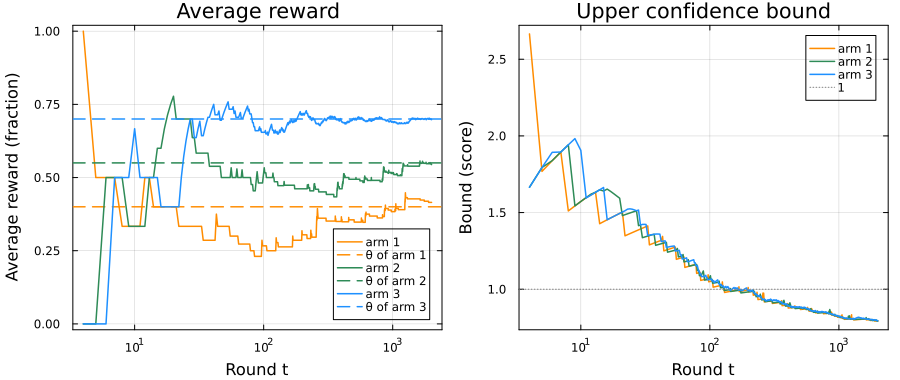

In [11]:
let

    # initialize -
    rounds = (K + 1):T; # the rounds with bounds: after each arm has one pull
    colors = [:darkorange, :seagreen, :dodgerblue]; # one color per arm
    left = plot(framestyle = :box, xscale = :log10, ylims = (-0.02, 1.02), xlabel = "Round t",
        ylabel = "Average reward (fraction)", title = "Average reward", legend = :bottomright,
        background_color = :transparent, background_color_inside = :transparent); # the left panel: averages are probabilities
    right = plot(framestyle = :box, xscale = :log10, xlabel = "Round t", ylabel = "Bound (score)",
        title = "Upper confidence bound", legend = :topright,
        background_color = :transparent, background_color_inside = :transparent); # the right panel: bounds are scores

    # the average, success probability, and bound of each arm -
    for a ∈ 1:K
        plot!(left, rounds, game.means[rounds, a], lw = 1.5, c = colors[a], label = "arm $(a)"); # solid line: the average reward of arm a
        hline!(left, [θ[a]], lw = 1.5, ls = :dash, c = colors[a], label = "θ of arm $(a)"); # dashed line: the success probability of arm a
        plot!(right, rounds, game.bounds[rounds, a], lw = 1.5, c = colors[a], label = "arm $(a)"); # solid line: the bound of arm a
    end
    hline!(right, [1.0], lw = 1, ls = :dot, c = :gray, label = "1"); # dotted line: no probability is larger than 1

    plot(left, right, layout = (1, 2), size = (900, 380), left_margin = 4Plots.mm, bottom_margin = 4Plots.mm,
        background_color = :transparent) # show the two panels side by side
end

__What do we see?__ On the left, the best arm's average settles near its success probability first, because UCB1 pulls it most. The averages of the other two arms jump around longer, but they also end near their success probabilities. 

On the right, the three bounds stay close together, because UCB1 pulls the arm with the largest bound, and that pull usually lowers it. The bounds start well above 1, because each arm has few pulls, and they fall below 1 only after many rounds. A bound above 1 tells us how little we know about an arm, not its chance of success.

### Which arms cost us reward?
The gap loss $G(T)$ adds up the gaps of the arms pulled in all $T$ rounds, so an arm pulled $N_{a}$ times adds $N_{a}\Delta(a)$. The regret $R(T)=T\mu^{\star}-(r_{1}+r_{2}+\dots+r_{T})$ compares the reward we collected with the reward we expect from $T$ pulls of the best arm. Let's tabulate the pulls and the cost of each arm, and compare the two:

In [12]:
let

    # initialize -
    μstar = maximum(θ); # μ⋆, the success probability of the best arm
    Δ = μstar .- θ; # the gap of each arm
    G = sum(Δ[a] for a ∈ game.actions); # gap loss G(T): add the gap of the arm pulled in each round
    R = T*μstar - sum(game.rewards); # regret R(T) = Tμ⋆ - (r₁ + r₂ + ... + r_T)

    # show the table -
    df = DataFrame(arm = 1:K, θ = θ, gap = round.(Δ, digits = 3), pulls = game.pulls,
        gap_loss = round.(game.pulls .* Δ, digits = 2)); # one row per arm; gap_loss = pulls × gap
    pretty_table(df; # print the table
        show_first_column_label_only = true, # show the column names only, not their types
        display_size = (-1, -1), # show every row and column
        alignment = :r # right-align every column
    );
    println("gap loss G(T) = ", round(G, digits = 2), ", regret R(T) = ", round(R, digits = 2)) # the two measures of cost

    # checks -
    @assert sum(game.pulls .* Δ) ≈ G # the costs of the arms add up to the gap loss
end

┌─────┬──────┬──────┬───────┬──────────┐
│ arm │    θ │  gap │ pulls │ gap_loss │
├─────┼──────┼──────┼───────┼──────────┤
│   1 │  0.4 │  0.3 │   106 │     31.8 │
│   2 │ 0.55 │ 0.15 │   248 │     37.2 │
│   3 │  0.7 │  0.0 │  1646 │      0.0 │
└─────┴──────┴──────┴───────┴──────────┘
gap loss G(T) = 69.0, regret R(T) = 72.0


__What do we see?__ The best arm got most of the pulls, but its gap is zero, so it cost nothing. Of the other two arms, the second-best arm has the smaller gap, so each of its pulls costs less. But its success probability is close to the best arm's, so UCB1 needs more experiments to tell the two apart. In our game, it got more pulls than the worst arm, and its total cost was larger.

The regret and the gap loss are close but not equal. The gap loss uses the success probabilities, while the regret uses the rewards we actually got, which depend on luck in each experiment. Averaged over many games, the two are equal. Your counts will differ if you change the seed.

___

## Summary
In this example, we set up a screening problem as a three-arm bandit, played the first rounds of UCB1 by hand, and played a full game to see where its cost comes from.

> __Key Takeaways:__
>
> * **A few experiments can rank the arms wrongly:** We ran a few experiments on each arm and saw a worse arm tie with or beat the best one. An agent that commits after a handful of pulls can pick the wrong arm.
> * **UCB1 is a short loop:** In each round, we computed the average, radius, and bound of each arm, and pulled the arm with the largest bound. A failure lowers an arm's bound, while the bounds of the skipped arms slowly rise, so UCB1 keeps returning to arms it knows little about.
> * **The hardest arm to rule out costs the most:** We played a full game, matched the course package round for round, and saw the best arm's average settle near its success probability. The second-best arm cost the most, because it is the hardest arm to tell apart from the best, so UCB1 pulled it more often.

We can now change the success probabilities, the number of rounds, or the seed and see how the pulls and the cost respond.

___